#ENTRENAMIENTO CON CARACTERISTICAS DE FRUTAS (NARANJAS)

-------

Carlos Francisco Montoya Urzua

Lunes, 25 de mayo de 2026

Montamos el drive

In [4]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


Creamos y entrenamos nuesto modelo tomando como base las caracteristicas extraidas en el programa extraccionCaracteristicasBase, en el cual se genero el archivo .csv

In [6]:
### **Código para entrenar el modelo con las características extraídas:**

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
# 1. Leer el archivo CSV con las características
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/CARACTERISTICAS_FRUTAS/caracteristicas_imagenes.csv')

# 2. Separar las características (X) y las etiquetas (y)
X = df.drop('etiqueta', axis=1)  # Las características (todas las columnas excepto 'etiqueta')
y = df['etiqueta']  # La etiqueta (la última columna)

# 3. Dividir los datos en conjunto de entrenamiento y conjunto de prueba (80% - 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# División con estratificación
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Estandarizar las características (normalizar los valores)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 5. Entrenar un modelo de clasificación (por ejemplo, Random Forest)
modelo = RandomForestClassifier(n_estimators=100, random_state=42)
modelo.fit(X_train, y_train)

# 6. Evaluar el modelo -- prediccion
y_pred = modelo.predict(X_test)

# 7. Mostrar los resultados

print("Precisión del modelo:", accuracy_score(y_test, y_pred))
print("Reporte de clasificación:\n", classification_report(y_test, y_pred, zero_division=0))
#print(classification_report(y_test, y_pred, zero_division=0))
#print(classification_report(y_test, y_pred, labels=[0], zero_division=0))
print("Clases reales en y_test:", y_test.value_counts())
print("Clases predichas en y_pred:", pd.Series(y_pred).value_counts())

Precisión del modelo: 0.0
Reporte de clasificación:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       1.0
           1       0.00      0.00      0.00       1.0
           2       0.00      0.00      0.00       0.0
           4       0.00      0.00      0.00       0.0

    accuracy                           0.00       2.0
   macro avg       0.00      0.00      0.00       2.0
weighted avg       0.00      0.00      0.00       2.0

Clases reales en y_test: etiqueta
0    1
1    1
Name: count, dtype: int64
Clases predichas en y_pred: 4    1
2    1
Name: count, dtype: int64


Copiamos del programa de extracionCaractaristicas, la funcion para extraer las caracteristicas de la imagen que vamos a clasificar unan vez entrenado nuesto modelo.

In [7]:
import cv2
import numpy as np
from skimage.feature import local_binary_pattern

def extraer_caracteristicas(image_array_norm):
    # `image_array_norm` is expected to be a NumPy array of shape (1, H, W, C) with pixel values normalized to [0, 1].

    # 1. Convert the normalized (0-1) RGB array to a 0-255 uint8 BGR array for OpenCV.
    # Remove the batch dimension (from (1, H, W, C) to (H, W, C))
    image_cv2_rgb = (image_array_norm[0] * 255).astype(np.uint8)

    # Convert RGB to BGR as OpenCV typically uses BGR by default
    imagen_bgr = cv2.cvtColor(image_cv2_rgb, cv2.COLOR_RGB2BGR)

    imagen_hsv = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2HSV)
    imagen_gray = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2GRAY)

    # 2. Histograma de color (HSV)
    hist_h = cv2.calcHist([imagen_hsv], [0], None, [8], [0, 180]).flatten()
    hist_s = cv2.calcHist([imagen_hsv], [1], None, [8], [0, 256]).flatten()
    hist_v = cv2.calcHist([imagen_hsv], [2], None, [8], [0, 256]).flatten()
    hist_color = np.concatenate((hist_h, hist_s, hist_v))
    hist_color = hist_color / (np.sum(hist_color) + 1e-7)  # normalización y evitar división por cero

    # 3. Características de forma: contornos
    _, binaria = cv2.threshold(imagen_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if contornos:
        mayor_contorno = max(contornos, key=cv2.contourArea)
        area = cv2.contourArea(mayor_contorno)
        perimetro = cv2.arcLength(mayor_contorno, True)
        momentos = cv2.moments(mayor_contorno)
        if momentos['m00'] == 0: momentos['m00'] = 1 # Avoid division by zero
        cx = int(momentos['m10'] / momentos['m00']) if momentos['m00'] != 0 else 0
        cy = int(momentos['m01'] / momentos['m00']) if momentos['m00'] != 0 else 0
    else:
        area = perimetro = cx = cy = 0

    forma = np.array([area, perimetro, cx, cy], dtype=np.float32)

    # 4. Características de textura: LBP
    lbp = local_binary_pattern(imagen_gray, P=8, R=1, method='uniform')
    # np.arange(0, 10) creates 9 bins for values 0-8
    (hist_lbp, _) = np.histogram(lbp.ravel(), bins=np.arange(0, 10), range=(0, 9))
    hist_lbp = hist_lbp.astype("float")
    hist_lbp /= (hist_lbp.sum() + 1e-7)

    # 5. Características de puntos clave: ORB
    orb = cv2.ORB_create()
    keypoints, descriptores = orb.detectAndCompute(imagen_gray, None)
    num_keypoints = len(keypoints)
    orb_feature = np.array([num_keypoints], dtype=np.float32)

    # 6. Concatenar todas las características
    # hist_color (24) + forma (4) + hist_lbp (9) + orb_feature (1) = 38 features
    vector_final = np.concatenate([hist_color, forma, hist_lbp, orb_feature])

    return vector_final
### **Ejemplo de uso:**


Seleccionamos y subimos la imagen a clasificar

In [8]:
#Subir un archivo en colab
from google.colab import files
uploaded = files.upload()


Saving naranja.jpg to naranja.jpg


Generamos la prediccion ya con la imagen que subimos para determinar su clasificacion.

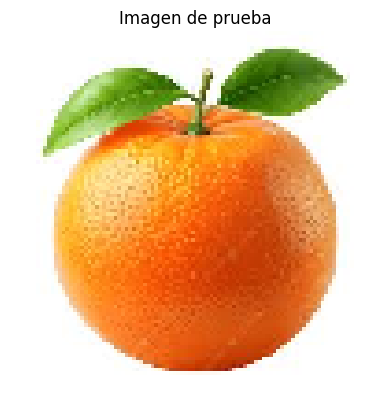

(38,)
[[-1.26933495  0.66650361  0.9679577   1.04427195  5.28959804  0.04381275
   4.17491384 -1.51475888  0.99893996 -0.40382275 -0.80166518  2.48798314
   5.31318217  6.08920458  2.93456791 -1.98388788 -0.681778   -0.83729445
  -1.02521987 -0.17493596 -0.42322239 -0.52415555  0.30990216  0.32785034
  -0.95597577 -0.84978137 -1.35390849 -1.35696233  3.84595259  1.04574823
  -0.03824298 -1.30011436 -1.21470444 -1.21342782 -2.81603927  2.13171997
   0.72688112 -6.36008841]]
Clase predicha: 3


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [9]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
img_path = list(uploaded.keys())[0]

# Cargar y preparar imagen
img = image.load_img(img_path, target_size=(100, 100))
img_array = image.img_to_array(img) / 255.0 # Scale pixels to [0, 1]
img_array = np.expand_dims(img_array, axis=0) # Add batch dimension (1, H, W, C)

# Mostrar imagen
plt.imshow(img)
plt.axis('off')
plt.title("Imagen de prueba")
plt.show()

features_for_prediction =extraer_caracteristicas(img_array)
print(features_for_prediction.shape)
# Escalar igual que entrenamiento
features_for_prediction = scaler.transform(features_for_prediction.reshape(1, -1))
print(features_for_prediction)
# Predecir
# After correct feature extraction and scaling, `features_for_prediction` should be ready.
pred = modelo.predict(features_for_prediction)
clase_predicha = pred[0] # RandomForestClassifier.predict() returns class labels directly
# etiquetas = list(modelo.classes_)
print("Clase predicha:", clase_predicha)